# Day 11 ? VAE augmentation for the rare Free Items category

Review the saved VAE training history, candidate-diversity measurement, and generated contact sheet. This notebook reports the existing run; it does not retrain the model. The candidate images were judged too blurry, so none were approved and no classifier accuracy lift is claimed.

## Review the saved run

To generate new candidates in an environment with TensorFlow and the catalog/model prerequisites, run `python src/day11_vae_augmentation.py --generate` from the repository root. Inspect the contact sheet before approving any images.

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
REPORTS = ROOT / 'reports'


In [2]:
history_path = REPORTS / 'day11_vae_training_history.csv'
quality_path = REPORTS / 'day11_vae_quality.csv'
assert history_path.exists(), f'Missing saved training history: {history_path}'
assert quality_path.exists(), f'Missing saved candidate report: {quality_path}'
history = pd.read_csv(history_path)
quality = pd.read_csv(quality_path)
print(f"Saved VAE epochs: {len(history)}")
display(history.tail())
display(quality)


Saved VAE epochs: 81


,epoch,kl_loss,loss,reconstruction_loss,val_kl_loss,val_loss,val_reconstruction_loss
76,77,34.335941,937.799622,903.463684,29.096951,1199.753418,1170.656494
77,78,30.622993,928.427979,897.805054,30.478832,1210.660400,1180.181519
78,79,31.844879,924.451965,892.606995,33.889091,1264.167236,1230.278198
79,80,32.557922,922.019775,889.461914,32.399010,1207.126831,1174.727905
80,81,34.528057,916.878052,882.350037,30.166355,1158.237183,1128.070801


,category,candidate_count,sampling_method,mean_pairwise_mse
0,Free Items,64,small perturbations around training posteriors,0.054242


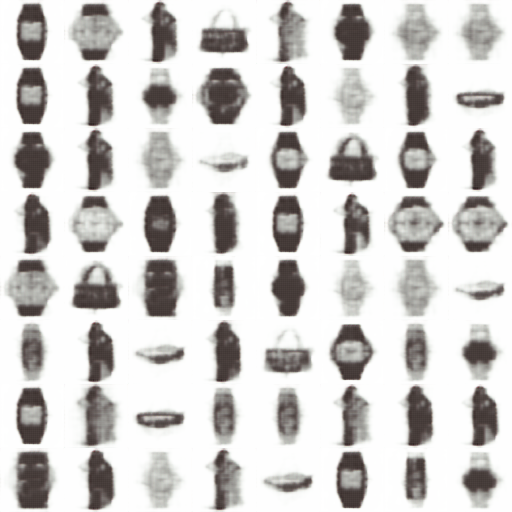

In [3]:
contact_sheet = REPORTS / 'day11_vae_candidates.png'
if contact_sheet.exists():
    display(Image(filename=str(contact_sheet)))
else:
    print('No candidate contact sheet is saved.')


In [4]:
tensorflow_available = importlib.util.find_spec('tensorflow') is not None
print(f'TensorFlow available for a fresh training run: {tensorflow_available}')
if not tensorflow_available:
    print('Fresh VAE training was not run in this environment. Existing saved history and candidates are shown above.')
print('Decision from the saved review: candidates were blurry; approved images: 0; classifier accuracy lift: not measured.')


TensorFlow available for a fresh training run: False
Fresh VAE training was not run in this environment. Existing saved history and candidates are shown above.
Decision from the saved review: candidates were blurry; approved images: 0; classifier accuracy lift: not measured.
